# Phase 2b · Validation 🔬
### Does the test find the real gene pairs, and are the pairs it finds real?

Phase 2 calls a gene pair with a **conditional pair test** that respects each tumour's own number of
alterations, fitted within subtypes. This notebook judges it with two measures, which matter equally:

| | Measure | Question | Perfect |
|---|---|---|---|
| 🎯 | **Precision** | Of the pairs the test calls, how many are real? | 100% |
| 🔍 | **Recall** | Of the real pairs, how many does the test find? | 100% |

A test can look good on one and fail the other: calling nothing gives no wrong calls but finds nothing;
calling everything finds every real pair among thousands of wrong ones. So every check below reports both,
and compares our test with the published methods **on identical data**:
Fisher's exact test (cBioPortal, maftools) · a DISCOVER-style test · SELECT (Mina 2017, re-implemented) · **ours**.

| § | Check | What it measures | Script |
|---|---|---|---|
| 1 | 🧹 Data with no real links | precision when nothing is real | `15_method_benchmark.py` |
| 2 | 🧪 Simulation with planted links | precision **and** recall, truth known | `22_planted_signal_simulation.py` |
| 3 | 📚 Known biology | recall of textbook pairs; are the top pairs real? | `data/curated/`, `19_novelty_screen.py` |
| 4 | 🌍 Independent patients (TCGA) | do the called pairs hold up elsewhere? | `14_tcga_external_validation.py` |

> ℹ️ The scripts take minutes to hours; this notebook only reads their saved outputs.
> The real-data method comparison and the mutation-load check are side checks in notebook 02c.

In [1]:
import numpy as np
import pandas as pd
from scipy.stats import false_discovery_control, spearmanr

P = "../data/processed/"
C = "../data/curated/"
pd.set_option("display.width", 160)
METHODS = {"Fisher": ("p_fisher", "dir_fisher"), "DISCOVER-style": ("p_discover", "dir_discover"),
           "SELECT": ("p_select", "dir_select"), "Ours": ("p_cond_subtype", "dir_cond_subtype")}


def qv(df, pc):   # SELECT reports its own q-values; the others use Benjamini-Hochberg
    return df["q_select"].to_numpy() if pc == "p_select" else false_discovery_control(df[pc].clip(1e-300, 1))


tv = pd.read_parquet(P + "tcga_validation.parquet")

---
## 1 · 🧹 Data with no real links: does the test call pairs that are not there?

The real data of 9 large cancer types are shuffled so that every patient keeps its number of alterations and
every gene its frequency, but any link between genes is destroyed (curveball swaps). **Every pair called here
is a wrong call**, so a precise test calls almost nothing. Share of pairs wrongly called at p < 0.05
(5% is expected by chance) and after the q < 0.05 cut-off (ideal: 0):

In [2]:
nb_null = pd.read_parquet(P + "method_benchmark_null.parquet")
pd.DataFrame([dict(method=n, wrongly_called_p05=(nb_null[pc] < .05).mean(), wrongly_called_q05=(qv(nb_null, pc) < .05).mean())
              for n, (pc, _) in METHODS.items()]).set_index("method").round(3)

,wrongly_called_p05,wrongly_called_q05
method,,
Fisher,0.114,0.006
DISCOVER-style,0.327,0.181
SELECT,0.038,0.002
Ours,0.019,0.000


A pair called in GENIE that is significant in the **opposite** direction in TCGA would also be a wrong call:

In [3]:
t = tv[tv.tcga_p.notna() & tv.interaction_candidate]
print(f"candidates testable in TCGA: {len(t)}; significant in TCGA in the opposite direction: "
      f"{int(((t.tcga_p < .05) & (t.tcga_direction != t.direction)).sum())}")

candidates testable in TCGA: 765; significant in TCGA in the opposite direction: 0


> 🧭 **Reading.** Fisher wrongly calls 11% of unlinked pairs and the DISCOVER-style test 33% (18% even after
> the q cut-off): both mistake a tumour's alteration load for a gene-gene link. Ours wrongly calls 2% (0% after
> the cut-off), SELECT 4%. No candidate is reversed in TCGA.

---
## 2 · 🧪 Simulation: precision and recall where the truth is known

Section 1 shows what happens when nothing is real, but says nothing about recall. Here, links of known
strength are **planted** into data that otherwise have none, and every method runs on the same data
(9 cancer types × 6 replicates × 3 scenarios).

**Three backgrounds**, so that the simulation is not set up to favour our test:

| Scenario | Background (no links) | Favours |
|---|---|---|
| **S1** model-based | drawn from our own gene + patient rate model, within subtypes | 🟦 us — a sanity check |
| **S2** real data, links removed | the real data, shuffled within subtypes (patients keep their counts, genes their frequencies) | ⚖️ no one — **realistic** |
| **S3** misspecified | S1 plus what our test does not model: a hidden patient group and 5% hypermutated-like patients | ⚠️ a stress test |

**Planted links:** 4 pairs per cancer type (no gene in common), co-occurring at 1.5×, 2× or 3× the background
number of patients with both, or exclusive at 1/1.5, 1/2 or 1/3. Gene B's alterations are moved between
patients with and without gene A, so B's frequency does not change. A planted pair counts as **found** only if
called (q < 0.05) **in the right direction**; every other call is wrong.

In [4]:
sim = pd.read_parquet(P + "simulation_planted.parquet")
SIM = {"Fisher": ("q_fisher", "p_fisher", "dir_fisher"), "DISCOVER-style": ("q_discover", "p_discover", "dir_discover"),
       "SELECT": ("q_select", "es_select", "dir_select"), "Ours": ("q_cond_subtype", "p_cond_subtype", "dir_cond_subtype")}
pos = sim.truth != "none"
print(f"per scenario: {pos.sum() // 3} planted links among {len(sim) // 3:,} tested pairs")
rows = []
for sc, s in sim.groupby("scenario"):
    p = pos.loc[s.index]
    for m, (qc, _, dc) in SIM.items():
        call = s[qc] < .05; hit = p & (s[dc] == s.truth)
        rows.append(dict(scenario=sc, method=m, calls=int(call.sum()),
                         precision=(call & hit).sum() / max(call.sum(), 1), recall=(call & hit).sum() / p.sum()))
pd.DataFrame(rows).set_index(["scenario", "method"]).round(3)

per scenario: 216 planted links among 15,318 tested pairs


calls  precision  recall
scenario                    method                                  
S1 model-based              Fisher           7630      0.018   0.634
                            DISCOVER-style   3163      0.044   0.644
                            SELECT            358      0.349   0.579
                            Ours              133      0.910   0.560
S2 real data, links removed Fisher           1833      0.074   0.625
                            DISCOVER-style   3594      0.035   0.583
                            SELECT            200      0.515   0.477
                            Ours              110      0.991   0.505
S3 misspecified             Fisher          10789      0.014   0.708
                            DISCOVER-style   4311      0.039   0.773
                            SELECT           2691      0.052   0.653
                            Ours             2066      0.075   0.718

### ⚖️ A fair comparison: recall at the same precision

At q < 0.05 each method calls a different number of pairs, and any method can raise its recall by calling
more pairs, at the cost of precision. So the fair question is: **when every method must keep the same
precision, which finds the most real links?** Pairs are ranked by each method's own score (p-value; SELECT by
its effect size) and recall is read at precision 95%, 90% and 80%. **AUPRC** = area under the
precision-recall curve (1 = perfect on both).

In [5]:
rows = []
for sc, s in sim.groupby("scenario"):
    n_pos = pos.loc[s.index].sum()
    for m, (_, sc_col, dc) in SIM.items():
        hit = (pos & (sim[dc] == sim.truth)).loc[s.index].to_numpy()
        score = (-s[sc_col] if sc_col == "es_select" else s[sc_col]).to_numpy()
        h = hit[np.argsort(score, kind="stable")]
        tp = np.cumsum(h); prec = tp / np.arange(1, len(h) + 1); rec = tp / n_pos
        r = dict(scenario=sc, method=m, AUPRC=np.sum(np.diff(np.r_[0, rec]) * prec))
        for level in (0.95, 0.90, 0.80):
            ok = prec >= level
            r[f"recall at precision {level:.0%}"] = rec[ok].max() if ok.any() else 0.0
        rows.append(r)
pd.DataFrame(rows).set_index(["scenario", "method"]).round(3)

AUPRC  recall at precision 95%  recall at precision 90%  recall at precision 80%
scenario                    method                                                                                          
S1 model-based              Fisher          0.112                    0.037                    0.037                    0.051
                            DISCOVER-style  0.089                    0.000                    0.000                    0.000
                            SELECT          0.393                    0.134                    0.148                    0.153
                            Ours            0.747                    0.565                    0.630                    0.667
S2 real data, links removed Fisher          0.187                    0.037                    0.037                    0.046
                            DISCOVER-style  0.097                    0.014                    0.014                    0.019
                            SELECT          0.392                    0.190                    0.218                    0.250
                            Ours            0.695                    0.569                    0.583                    0.634
S3 misspecified             Fisher          0.169                    0.079                    0.083                    0.083
                            DISCOVER-style  0.132                    0.028                    0.028                    0.037
                            SELECT          0.304                    0.153                    0.153                    0.171
                            Ours            0.280                    0.046                    0.051                    0.060

### 🔍 Which links are found? Recall by planted strength (S2, realistic)

In [6]:
s2 = sim[sim.scenario == "S2 real data, links removed"]
s2p = s2[s2.truth != "none"]
pd.DataFrame({m: ((s2p[qc] < .05) & (s2p[dc] == s2p.truth)).groupby([s2p.truth, s2p.fold]).mean()
              for m, (qc, _, dc) in SIM.items()}).round(2)

Fisher  DISCOVER-style  SELECT  Ours
truth        fold                                      
co-occurring 1.5     0.47            0.08    0.19  0.22
             2.0     0.86            0.42    0.25  0.67
             3.0     0.92            0.81    0.64  0.89
exclusive    1.5     0.33            0.64    0.42  0.31
             2.0     0.39            0.67    0.61  0.39
             3.0     0.78            0.89    0.75  0.56

### 🎚️ Would a looser cut-off help? Our test at several q thresholds (S2)

In [7]:
h2 = (s2.truth != "none") & (s2.dir_cond_subtype == s2.truth)
pd.DataFrame([dict(q_threshold=t, precision=((s2.q_cond_subtype < t) & h2).sum() / max((s2.q_cond_subtype < t).sum(), 1),
                   recall=((s2.q_cond_subtype < t) & h2).sum() / (s2.truth != "none").sum())
              for t in (0.05, 0.1, 0.2, 0.3)]).round(3)

,q_threshold,precision,recall
0,0.05,0.991,0.505
1,0.10,0.959,0.542
2,0.20,0.905,0.574
3,0.30,0.876,0.588


> 🧭 **Reading.**
>
> | Realistic data (S2), q < 0.05 | 🎯 Precision | 🔍 Recall |
> |---|---|---|
> | **Ours** | **99%** | 51% |
> | SELECT | 52% | 48% |
> | Fisher | 7% | 63% |
> | DISCOVER-style | 3.5% | 58% |
>
> - ✅ **Ours is the only method with both high precision and comparable recall.** Fisher and DISCOVER-style
>   reach slightly higher recall only by calling thousands of pairs, at a precision of 3.5-7%.
> - ✅ **At the same precision, ours finds the most:** at 95% precision it finds 57% of planted links,
>   SELECT 19%, Fisher and DISCOVER-style 4% or less.
> - 🔍 **What ours misses:** weak co-occurrence (1.5×) and part of the exclusive links (31-56% found vs
>   64-89% for DISCOVER-style). Avoidance is harder to detect -- it is a shortfall of patients with both,
>   bounded at zero -- and DISCOVER-style's higher recall here comes with its bias towards exclusivity.
> - 🎚️ A looser cut-off (q < 0.2) raises recall by 7 points but lowers precision to 90%, so no second tier
>   is added.
> - 🟦 **S1** (our own assumption): precision 91%; every wrong call shares a gene with a planted link -- a
>   by-product of moving alterations when planting. Among unlinked pairs only 2.4% reach p < 0.05.
> - ⚠️ **S3 is a limit for every method, ours included** (precision 1-8%): a strong hidden patient group that
>   no test sees creates real but indirect associations. The test is only as good as its strata -- which is
>   why Phase 2 fits rates within detailed subtypes and analyses hypermutated tumours separately.

---
## 3 · 📚 Known biology

### 3a · Recall of textbook pairs
29 pairs with a published direction, chosen from the literature **before** looking at our results
(`data/curated/textbook_pairs.csv`, each with a reference and DOI), all present in the 9 benchmark cancer types.
Found = called (q < 0.05) in the published direction.

In [8]:
mb = pd.read_parquet(P + "method_benchmark.parquet")
tb = pd.read_csv(C + "textbook_pairs.csv")
q = {m: qv(mb, pc) for m, (pc, _) in METHODS.items()}
rows = []
for r in tb.itertuples():
    k = mb.index[(mb.Cancer_Type == r.Cancer_Type) & (((mb.Gene_A == r.Gene_A) & (mb.Gene_B == r.Gene_B))
                                                     | ((mb.Gene_A == r.Gene_B) & (mb.Gene_B == r.Gene_A)))][0]
    i = mb.index.get_loc(k)
    rows.append({"pair": f"{r.Gene_A} + {r.Gene_B}", "cancer type": r.Cancer_Type, "published": r.expected_direction,
                 **{m: "✅" if q[m][i] < .05 and mb.loc[k, dc] == r.expected_direction else "—"
                    for m, (_, dc) in METHODS.items()}, "reference": r.reference})
tt = pd.DataFrame(rows)
print("recall of textbook pairs:", {m: f"{(tt[m] == '✅').sum()}/{len(tt)}" for m in METHODS})
tt[tt[list(METHODS)].eq("—").any(axis=1)]   # only the pairs some method misses

recall of textbook pairs: {'Fisher': '28/29', 'DISCOVER-style': '27/29', 'SELECT': '27/29', 'Ours': '26/29'}


,pair,cancer type,published,Fisher,DISCOVER-style,SELECT,Ours,reference
9,CDH1 + PIK3CA,Breast Cancer,co-occurring,✅,—,✅,✅,Ciriello 2015 Cell
10,PIK3CA + PTEN,Breast Cancer,exclusive,✅,✅,—,—,Saal 2005 Cancer Res
13,BRAF + NRAS,Colorectal Cancer,exclusive,—,✅,—,—,TCGA 2012 Nature (colorectal)
21,PIK3CA + PTEN,Endometrial Cancer,co-occurring,✅,—,✅,—,Oda 2005 Cancer Res


> 🧭 Every method finds the strong, famous pairs. Ours misses three weaker ones (PIK3CA + PTEN in breast and
> endometrial cancer, BRAF + NRAS in colorectal cancer) -- the recall cost of a more precise test, consistent
> with the simulation, where weak and exclusive links are the ones most often missed.

### 3b · Are the strongest pairs real? (precision at the top)
Among robust pairs (replicated outside MSK, burden-robust, not weak) with q < 1e-10, the 10 largest effects per
direction, each checked against the literature (`data/curated/top_pairs_biology.csv`).

In [9]:
cp = pd.read_parquet(P + "comutation_pairs.parquet")
bio = pd.read_csv(C + "top_pairs_biology.csv")
r = cp[cp.interaction_candidate & cp.replicated & ~cp.weak_effect & (cp.q_value < 1e-10)].copy()
r["abs_effect"] = r.log2_fold_enrichment.abs()
top = pd.concat([r[r.direction == d].nlargest(10, "abs_effect") for d in ["co-occurring", "exclusive"]])
top = top.merge(bio, on=["Cancer_Type", "Gene_A", "Gene_B", "direction"], how="left")
display(top[["Cancer_Type", "Gene_A", "Gene_B", "direction", "n_both_altered", "expected_both", "fold_enrichment",
             "status", "biology", "reference"]].round(2))
top.groupby("direction").status.value_counts()

,Cancer_Type,Gene_A,Gene_B,direction,n_both_altered,expected_both,fold_enrichment,status,biology,reference
0,Non-Small Cell Lung Cancer,KEAP1,STK11,co-occurring,689,159.73,4.30,known,KRAS-STK11-KEAP1 (KL) subgroup of lung adenoca...,Skoulidis 2015 Cancer Discov
1,Non-Small Cell Lung Cancer,BRAF,SETD2,co-occurring,87,22.59,3.79,to check,few reports; no established mechanism,NaN
2,Non-Small Cell Lung Cancer,CTNNB1,SMAD4,co-occurring,51,15.22,3.28,to check,few reports; no established mechanism,NaN
3,Non-Small Cell Lung Cancer,KEAP1,SMARCA4,co-occurring,230,71.23,3.21,known,SMARCA4 alterations co-occur with KEAP1 and ST...,Schoenfeld 2020 Clin Cancer Res
4,Glioma,NF1,PTPN11,co-occurring,100,33.10,2.99,to check,two RAS-pathway hits that co-occur; an excepti...,NaN
5,Non-Small Cell Lung Cancer,CDK4,MET,co-occurring,101,35.20,2.84,known,CDK4 amplification is common in MET exon 14 sk...,Schrock 2016 J Thorac Oncol
6,Non-Small Cell Lung Cancer,SMARCA4,STK11,co-occurring,243,86.23,2.81,known,SMARCA4 alterations co-occur with KEAP1 and ST...,Schoenfeld 2020 Clin Cancer Res
7,Non-Small Cell Lung Cancer,MDM2,MET,co-occurring,152,54.91,2.75,known,MDM2 amplification is common in MET exon 14 sk...,Schrock 2016 J Thorac Oncol
8,Breast Cancer,CD79B,GATA3,co-occurring,259,98.14,2.63,artefact suspected,likely a subtype marker: CD79B lies in the 17q...,NaN
9,Prostate Cancer,APC,SPOP,co-occurring,107,44.35,2.40,to check,few reports; no established mechanism,NaN


direction     status            
co-occurring  known                  5
              to check               4
              artefact suspected     1
exclusive     known                 10
Name: count, dtype: int64

> 🧭 **Exclusive:** all 10 are established biology -- alternative drivers (ALK fusion vs EGFR / KRAS, GNAQ vs
> GNA11) and subgroup markers (H3F3A vs IDH1, ERG fusion vs SPOP).
> **Co-occurring:** 5 established (KEAP1 / STK11 / SMARCA4 in lung cancer; MDM2 and CDK4 amplification with MET),
> 1 suspected artefact (CD79B + GATA3, a luminal subtype marker), and 4 not yet explained -- 🔎 the candidates
> worth a closer look: BRAF + SETD2, CTNNB1 + SMAD4 (lung), NF1 + PTPN11 (glioma), APC + SPOP (prostate).

### 3c · All robust pairs vs the literature and the SelectSim atlas
SelectSim (Iyer 2026) covers mutations only, so copy-number and fusion pairs cannot appear in it.

In [10]:
nv = pd.read_parquet(P + "novelty_screen.parquet")
display(pd.DataFrame({"robust pairs": nv.novelty.value_counts()}))
display(pd.DataFrame({"robust pairs": nv.selectsim.value_counts()}))

,robust pairs
novelty,
well known,234
some reports,109
rarely or never reported,43


,robust pairs
selectsim,
not reported,245
"same type, same direction",79
pan-cancer only,62


---
## 4 · 🌍 Independent patients: TCGA

The same test, re-run on different patients (TCGA PanCancer Atlas: whole exome, other centres and callers,
non-hypermutated, TCGA study as the subtype stratum). **Nothing is fitted again** -- each pair is simply
re-tested. TCGA has about 1/20 of GENIE's patients, so **direction** and **effect size** are the main measures;
significance in TCGA mostly reflects how many TCGA patients carry the pair.

**Control** = pairs *not* called in GENIE: they show how much agreement to expect without a real link.

In [11]:
t = tv[tv.tcga_p.notna()]
g = lambda d: np.log2((d.n_both_altered + .5) / (d.expected_both + .5))
k = lambda d: np.log2((d.tcga_n_both + .5) / (d.tcga_expected + .5))
rows = []
for name, sel in [("replicated candidates", t.interaction_candidate & t.replicated),
                  ("all candidates", t.interaction_candidate), ("control: not called in GENIE", t.q_value >= .05)]:
    d = t[sel]; same = d.tcga_direction == d.direction; pw = d.tcga_expected >= 20
    rows.append({"group": name, "testable": len(d), "same direction": f"{same.sum()} ({same.mean():.0%})",
                 "effect correlation (Spearman)": round(spearmanr(g(d), k(d))[0], 2),
                 "significant, same direction (TCGA expected >= 20)": f"{((d.tcga_p < .05) & same)[pw].mean():.0%} of {pw.sum()}"})
pd.DataFrame(rows).set_index("group")

,testable,same direction,effect correlation (Spearman),"significant, same direction (TCGA expected >= 20)"
group,,,,
replicated candidates,316,297 (94%),0.82,64% of 107
all candidates,765,675 (88%),0.74,46% of 200
control: not called in GENIE,1317,907 (69%),0.43,7% of 244


**Stronger in GENIE → more often confirmed in TCGA.** Candidates in four equal groups by GENIE q-value:

In [12]:
c = t[t.interaction_candidate].copy()
c["GENIE strength"] = pd.qcut(c.q_value.rank(method="first"), 4, labels=["strongest quarter", "2nd", "3rd", "weakest quarter"])
same = c.tcga_direction == c.direction
c.assign(same_direction=same, significant_same_direction=same & (c.tcga_p < .05)) \
 .groupby("GENIE strength", observed=True)[["same_direction", "significant_same_direction"]].mean().round(2)

,same_direction,significant_same_direction
GENIE strength,,
strongest quarter,0.98,0.66
2nd,0.91,0.29
3rd,0.86,0.20
weakest quarter,0.78,0.15


> 🧭 Candidates keep their direction in TCGA far more often than control pairs (88% vs 69% -- the control's
> 69% shows that direction alone is weak evidence), their effect sizes correlate across the two cohorts (0.74),
> and agreement rises with the strength of the GENIE signal. Where TCGA has enough patients (expected >= 20
> with both), candidates are significant there several times more often than controls.

---
### 📊 Figure -- Phase 2b at a glance
**a** 🎯 precision of each method at q < 0.05 in the three scenarios · **b** 🔍 recall by planted strength (S2) ·
**c** precision-recall curves, circles = q < 0.05 (S2) · **d** 📚 textbook pairs found in real data ·
**e** 🌍 effect in GENIE vs TCGA for every candidate.  \n*Drawn by `scripts/figures/phase2b_validation.R` ->
`results/figures/phase2b_validation/figure_phase2b.pdf`*

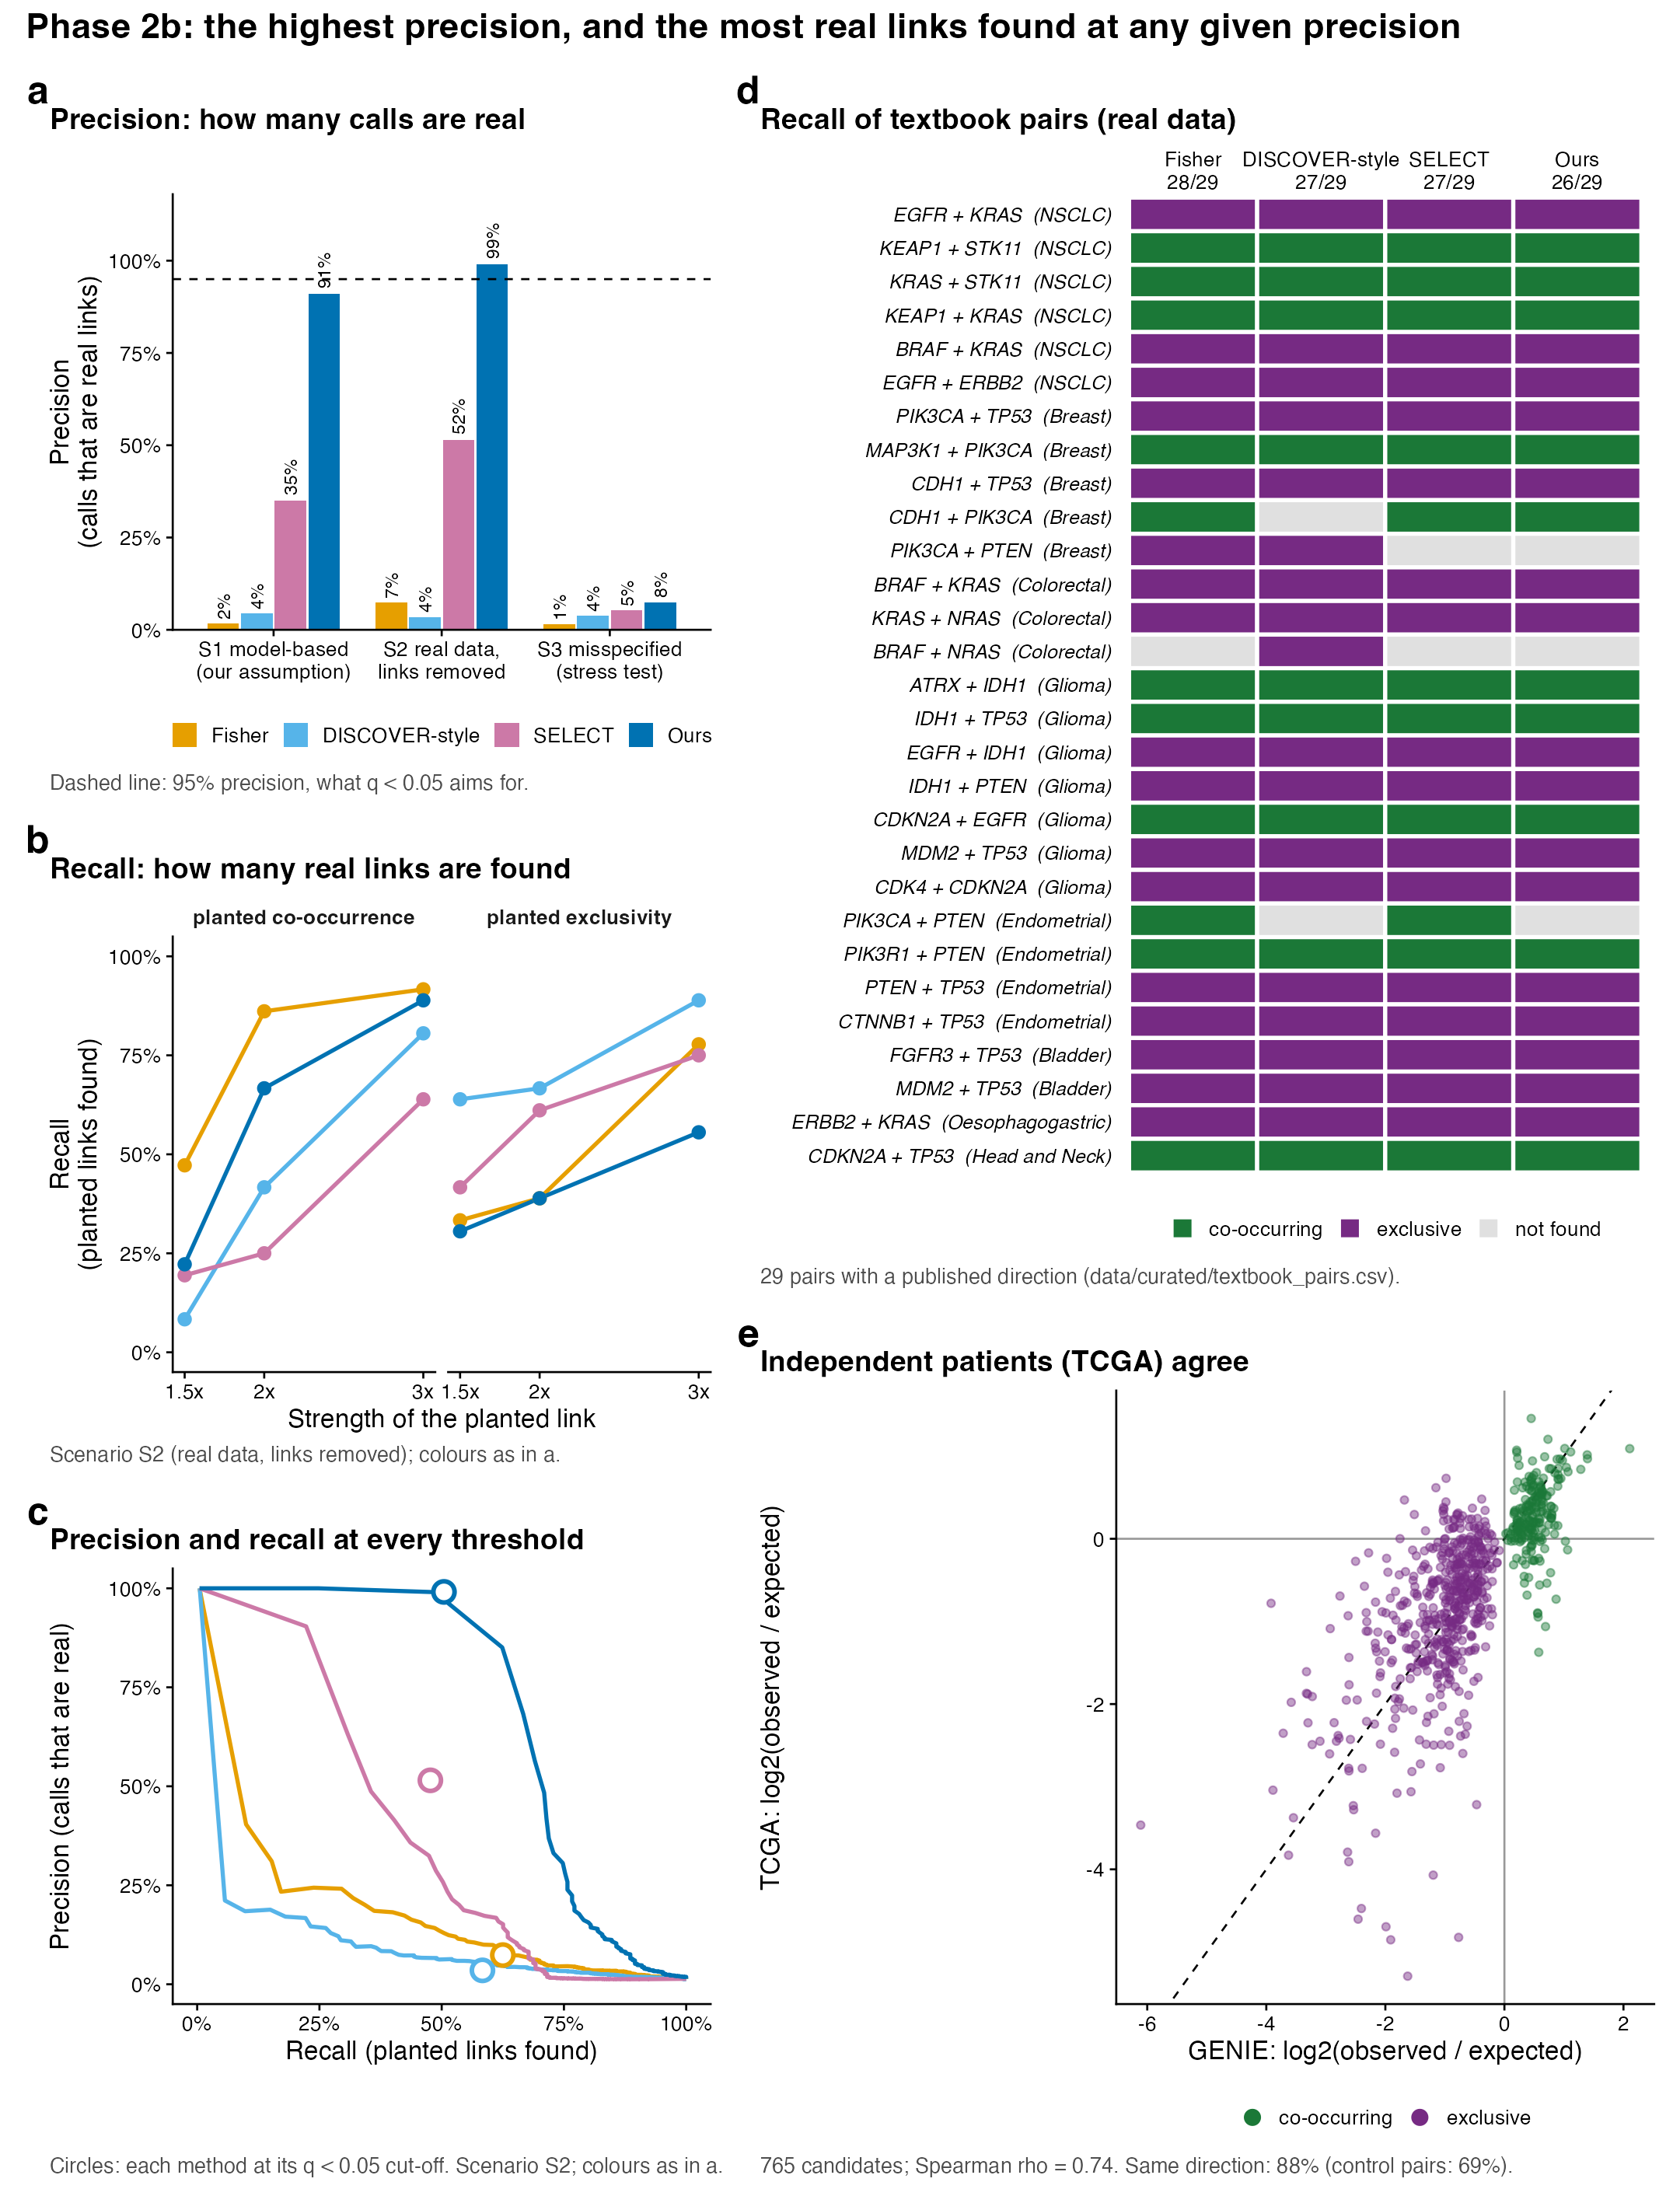

In [13]:
import subprocess, sys
from IPython.display import Image, display

# Rebuild this figure from the saved outputs: export small CSVs, then run the R script
subprocess.run([sys.executable, "scripts/figures/00_export_figure_data.py"], cwd="..", check=True, capture_output=True)
subprocess.run(["Rscript", "scripts/figures/phase2b_validation.R"], cwd="..", check=True, capture_output=True)
display(Image(filename="../results/figures/phase2b_validation/figure_phase2b.png", width=1000))

---
## ✅ Summary

| | 🎯 Precision | 🔍 Recall |
|---|---|---|
| 🧹 No real links | ours wrongly calls 2% of pairs (0% after q < 0.05); Fisher 11%, DISCOVER-style 33% | -- |
| 🧪 Simulation (realistic) | **99%** (SELECT 52%, Fisher 7%, DISCOVER-style 3.5%) | 51% (others 48-63%); **57% at 95% precision** vs ≤ 19% for the others |
| 📚 Known biology | all 10 strongest exclusive pairs established; 5 of 10 co-occurring | 26 of 29 textbook pairs (others 27-28) |
| 🌍 TCGA | 0 candidates reversed; 88% same direction (control 69%) | -- |

1. 🎯 **Precision:** ours is the only method whose calls are almost all real.
2. 🔍 **Recall:** comparable to the others at q < 0.05, and far higher when every method must keep the same
   precision. It misses weak co-occurrence and part of the exclusive links; no cut-off recovers them cheaply.
3. ⚠️ **Limit:** a hidden patient group that the subtype strata do not capture breaks every method (S3). The
   subtype strata and the separate hypermutated analysis are therefore part of the method, not options.